In [37]:
#@title

%matplotlib inline
#%matplotlib notebook
%reload_ext autoreload
%autoreload 2

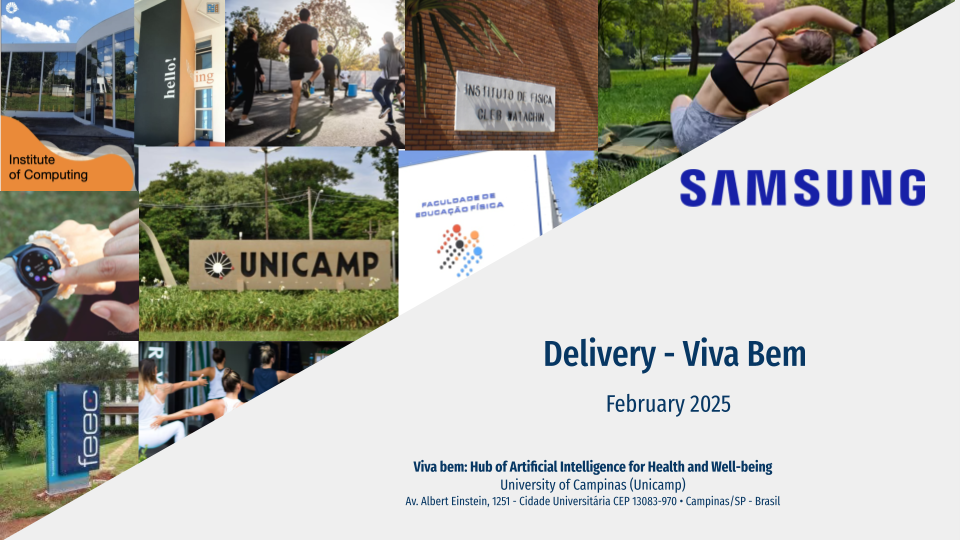


---
---   
    
# <center> A2 - Human Activity Recognition </center>

---
---

## <center> Abstract </center>

Human Activity Recognition (HAR) has emerged as a prominent topic in the field of Machine Learning (ML), particularly in the context of mobile devices. Modern mobile devices are equipped with sensors capable of collecting real-time user data, enabling the detection of individual patterns. The primary goal of HAR is to design and implement models that accurately detect and classify human activities. This capability holds significant potential for applications in healthcare, fitness, smart environments, and beyond, making it a critical area of research and development. This project focuses on designing a model optimized for mobile devices with limited resources while maintaining high performance. To achieve this, we utilized benchmark datasets and various ML techniques. The proposed model is a lightweight Convolutional Neural Network (LWCNN) that utilizes recurrence plots generated from the accelerometer data on the x, y, and z axes to effectively process sensor data and classify four human activities: jogging, walking, standing, and sitting.

---
---   
    
## <center> 1. Lib loading and properties definition </center>

In [38]:
import time
import os

from collections import OrderedDict
from typing import List, Tuple

import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, random_split

from torchsummary import summary
from torchvision import models

from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, confusion_matrix, ConfusionMatrixDisplay

import flwr
from flwr.client import Client, NumPyClient
from flwr.server import ServerConfig
from flwr.common import Metrics
from flwr.server.strategy import FedAvg
from flwr.simulation import start_simulation

In [39]:
DEVICE = torch.device("cpu")  # Try "cuda" to train on GPU
print(f"Training on {DEVICE}")
print(f"Flower {flwr.__version__} / PyTorch {torch.__version__}")

# Define the path to the dataset and the sequence length
PATH = '../datasets/'
NUM_CLIENTS_TRAIN = 27
NUM_CLIENTS_TEST = 9
NUM_CLASSES = 4
LEARNING_RATE = 5e-6
NUM_ROUNDS = 30
NUM_EPOCHS = 10
WINDOW_SIZE = 128
STRIDE = 48
BATCH_SIZE = 32

Training on cpu
Flower 1.7.0 / PyTorch 2.2.1+cu121


---
---   
    
## <center> 2. Data </center>

In [40]:
#from google.colab import drive
#drive.mount('/content/drive')

#Read folders
#path = '/content/drive/Shareddrives/Viva_Bem/entregáveis_software/7th_delivery(January2024)/a2_activity_recognition/data'
#folders = os.listdir(path)

## WISDM Dataset

The Wireless Sensor Data Mining (WISDM) dataset is a well-known collection used for Human Activity Recognition (HAR). It contains accelerometer data from mobile devices, collected while users perform various activities such as walking, jogging, sitting, and standing. The dataset includes three accelerometer axes (x, y, z) along with activity labels and timestamps.

The WISDM dataset is widely used to train machine learning models to classify and recognize human activities based on sensor readings. It consists of data from 36 users, each performing multiple activities, providing a rich set of data points for HAR tasks.

## Pre-Processing 

The provided dataset was pre-processed using the following steps. The original dataset can be downloaded at this [link](https://www.cis.fordham.edu/wisdm/dataset.php).

1. **Reading the Data:**  
   The dataset is loaded into a pandas DataFrame from a `.txt` file, with the appropriate delimiter and without headers. Any malformed lines are skipped during this process.

2. **Column Naming:**  
   Since the dataset lacks headers, explicit column names are assigned for clarity: `user_id`, `activity`, `timestamp`, `x`, `y`, and `z`.

3. **Cleaning the 'z' Column:**  
   The 'z' accelerometer values may contain a trailing semicolon (`;`), which is removed using the `rstrip()` function. The values are then converted to floats for further processing.

4. **Balancing the Dataset:**  
   The dataset may suffer from class imbalance (unequal distribution of activity labels). To address this, the dataset is balanced by resampling the underrepresented classes so that each class has the same number of samples. This ensures fair training for machine learning models.

5. **Sorting the Data:**  
   After balancing, the dataset is sorted by `user_id` and `timestamp`, ensuring that the data is ordered chronologically and grouped by users.

6. **Saving the Processed Data:**  
   Finally, the pre-processed and balanced dataset is saved to a new CSV file for later use.

These pre-processing steps help to clean the data, address class imbalance, and ensure the dataset is ready for the next processing steps.


### Reading and Preparing the dataset

This code preprocesses the WISDM dataset by filtering specific activities (`Walking`, `Jogging`, `Sitting`, and `Standing`) and normalizing accelerometer readings (`x`, `y`, `z`) for each user individually. The filtering ensures that only relevant classes are included for the classification task. Normalization is performed using z-score normalization, which transforms each value using the formula:

$$
z = \frac{x - \mu}{\sigma}
$$

Where $x$ is the original accelerometer value, $\mu$ is the mean of the user's data for the axis, and $\sigma$ is the standard deviation. This process results in data with a mean of 0 and a standard deviation of 1, standardizing the scale for each user's data.

By treating each user as an independent "island" of data, the normalization ensures that variations between users do not affect the model's learning process. This preprocessing step is critical for improving the model's ability to generalize across users and achieve better performance in distinguishing activities.


In [41]:

# Function to normalize columns
def normalize_group(group):
    group[['x', 'y', 'z']] = (group[['x', 'y', 'z']] - group[['x', 'y', 'z']].mean()) / group[['x', 'y', 'z']].std()
    return group

# Load data from file
df = pd.read_csv(f"{PATH}/WISDM_ar_v1.1_balanced.csv", header=None, names=['user_id', 'activity', 'timestamp', 'x', 'y', 'z'])
if(NUM_CLASSES == 4):
    # Filter for specific activities
    df = df.loc[
        (df['activity'] == 'Walking') | 
        (df['activity'] == 'Jogging') | 
        (df['activity'] == 'Sitting') | 
        (df['activity'] == 'Standing') 
    ].reset_index(drop=True)

df = df.groupby('user_id').apply(normalize_group)
    
# Map activities to integers if not already done
activity_mapping = {activity: idx for idx, activity in enumerate(df['activity'].unique())}
df['activity'] = df['activity'].map(activity_mapping)

# Split the dataset by user_id
user_ids = df['user_id'].unique()
user_ids

/tmp/ipykernel_1327506/595408027.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('user_id').apply(normalize_group)


array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36])

In [42]:
activity_mapping

{'Walking': 0, 'Jogging': 1, 'Sitting': 2, 'Standing': 3}

The **`recurrence_plot_vector`** function is used to generate a binary recurrence plot for a vector sequence using a specified threshold. It calculates pairwise Euclidean distances between vectors in a sequence and determines whether these distances fall below the threshold (`eps`). The output is a binary recurrence matrix.

#### Inputs:  
- **`data`**: A PyTorch tensor with shape $(N, D)$, where $N$ is the number of vectors in the sequence and $D$ is the dimensionality of each vector.  
- **`eps`**: A float specifying the threshold for recurrence.

#### Computation:  
1. The function ensures the input is a tensor and converts it to a 32-bit float tensor.  
2. It computes pairwise Euclidean distances between vectors using the formula:
   $
   d(v_i, v_j) = \sqrt{\sum_{k=1}^{D} (v_i[k] - v_j[k])^2}
   $
3. A binary recurrence matrix is generated based on the threshold:
   $
   R_{ij} =
   \begin{cases} 
   1 & \text{if } d(v_i, v_j) \leq \epsilon, \\ 
   0 & \text{otherwise.}
   \end{cases}
   $

#### Output:  
- **`recurrence_matrix`**: A binary tensor of shape $(N, N)$, where $R_{ij}$ indicates whether the distance between vectors $v_i$ and $v_j$ is below the threshold.


In [43]:
def recurrence_plot_vector(data, eps):
    """
    Generate a recurrence plot for a vector sequence using a specified threshold.
    
    Parameters:
    - data: torch.Tensor, shape (N, D), where N is the number of vectors and D is their dimensionality.
    - eps: float, the threshold for recurrence.

    Returns:
    - recurrence_matrix: torch.Tensor, shape (N, N), binary recurrence matrix.
    """
    # Ensure the input is a tensor on the correct device
    if not isinstance(data, torch.Tensor):
        raise ValueError("Input data must be a PyTorch tensor.")
    
    # Compute pairwise Euclidean distances using PyTorch broadcasting
    data = data.to(torch.float32)  # Ensure correct dtype for computation
    distances = torch.cdist(data, data, p=2)  # Compute pairwise distances

    # Apply the threshold
    recurrence_matrix = (distances <= eps).int()

    return recurrence_matrix


The **`preprocess_and_save_recurrence_plots`** function preprocesses a dataset to generate multi-channel recurrence plots for sequences of data and saves the results to disk.

#### Inputs:  
- **`df`**: A pandas DataFrame containing columns `'x'`, `'y'`, `'z'`, and `'activity'`.  
- **`thresholds`**: A list of float values specifying thresholds for recurrence plots.  
- **`sequence_length`**: The number of consecutive data points to include in each sequence.  
- **`stride`**: The step size between sequences.  
- **`save_path`**: Path to save the processed data as a `.pt` file.

#### Procedure:  
1. The function iterates over the dataset, extracting windows of size `sequence_length` with a step size of `stride`.  
2. Each window is transformed into a sequence of vectors:
   $$
   V = \{v_1, v_2, \dots, v_n\} = \{(x_1, y_1, z_1), (x_2, y_2, z_2), \dots, (x_n, y_n, z_n)\},
   $$
   where $n$ = sequence_length.
3. For each threshold in `thresholds`, the **`recurrence_plot_vector`** function is applied to generate a recurrence plot. These are stacked along a new dimension to create multi-channel recurrence plots.  
4. The activity label of the last sample in the sequence is assigned as the sequence's label.

#### Outputs:  
The processed data and labels are saved to the specified `save_path` as a PyTorch dictionary:
- `'data'`: A tensor of shape (`num_sequences`, `sequence_length`, `sequence_length`, `num_channels`).  
- `'labels'`: A tensor of shape (`num_sequences`, ), containing the activity labels.

#### Example Recurrence Plot Generation:
- For each sequence, four recurrence plots are generated using different thresholds.  
- Each plot highlights the pairwise relationships between vectors in the sequence under the specified threshold.

#### Final Saved Format:
The recurrence plots are saved alongside their labels for future training and evaluation tasks, enabling the model to learn patterns in human activity recognition or similar tasks.


In [44]:
def preprocess_and_save_recurrence_plots(df, thresholds, sequence_length=50, stride=1, save_path="processed_data.pt"):
    """
    Preprocess the dataset to generate recurrence plots and save them.

    Parameters:
    - df: DataFrame containing the data.
    - thresholds: list of floats, thresholds for recurrence plots.
    - sequence_length: int, length of each sequence.
    - stride: int, step size between sequences.
    - save_path: str, path to save the preprocessed data.

    Returns:
    - None
    """
    try:
        processed_data = []
        labels = []

        if os.path.exists(save_path):
            print(f"File {save_path} already exists. Skipping preprocessing.")
            return

        for idx in range(0, len(df) - sequence_length + 1, stride):
            # Select a window of data points
            window = df.iloc[idx:idx + sequence_length]

            # Extract x, y, z values
            sequence = torch.tensor(window[['x', 'y', 'z']].values, dtype=torch.float32)

            # Generate multi-channel recurrence plots
            recurrence_plots = torch.stack(
                [recurrence_plot_vector(sequence, threshold) for threshold in thresholds], dim=-1
            )

            # The label is the activity of the last element in the sequence
            label = int(window.iloc[-1]['activity'])

            processed_data.append(recurrence_plots)
            labels.append(label)

        # Convert to tensors
        processed_data = torch.stack(processed_data)  # Shape: (num_sequences, sequence_length, sequence_length, num_channels)
        labels = torch.tensor(labels, dtype=torch.long)  # Shape: (num_sequences,)

        # Save to disk
        torch.save({'data': processed_data, 'labels': labels}, save_path)
        print(f"Preprocessed data saved to {save_path}")

    except Exception as e:
        print(f"An error occurred during preprocessing: {e}")


The thresholds used to create the recurrence plots are defined arbitrarily using visual information from generated plot as example. Thousand plots were generated with a list of fifty different values for threshold. From these examples, 4 threshold values were chosen, one representing each of the four analysed activities from the dataset (walking, jogging, sitting and standing). Each threshold will generate a separate channel for the final input, resulting in a shape of \(`WINDOW_SIZE`, `WINDOW_SIZE`, 4).


In [45]:
THRESHOLDS = [
    1.0000, 
    0.0187, 
    0.0113, 
    1.0000
]  # List of thresholds

This snippet preprocesses data for each user in the dataset by filtering rows for each unique `user_id`. The **`preprocess_and_save_recurrence_plots`** function generates recurrence plots for sequences of length `WINDOW_SIZE` using thresholds in `THRESHOLDS` and saves the results as `processed_user_{user_id}.pt`. Each user's data is handled and saved separately to ensure isolation.


In [46]:
for user_id in df['user_id'].unique():
    user_df = df[df['user_id'] == user_id]
    preprocess_and_save_recurrence_plots(
        user_df,
        thresholds=THRESHOLDS,
        sequence_length=WINDOW_SIZE,
        stride=STRIDE,
        save_path=f"{PATH}/processed_user_{user_id}.pt"
    )


File ../datasets//processed_user_1.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_2.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_3.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_4.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_5.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_6.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_7.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_8.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_9.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_10.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_11.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_12.pt already exists. Skipping preprocessing.
File ../datasets//processed_user_13.pt already exists. Skippi

The **`WISDMDataset`** class is a PyTorch `Dataset` designed to load precomputed recurrence plot data for use in machine learning models. It simplifies data handling and ensures compatibility with PyTorch's DataLoader.

- **Parameters**:
  - `processed_data_path`: A string specifying the path to the preprocessed data file saved as a `.pt` file.
- **Process**:
  1. Loads the `.pt` file using `torch.load()`.
  2. Converts the data to 32-bit float tensors and permutes the dimensions to match PyTorch's expected format: (`batch`, `channels`, `height`, `width`).
  3. Converts the labels to 64-bit integers.

#### Methods:
1. **`__len__`**:
   - **Purpose**: Returns the total number of samples in the dataset.
   - **Usage**: Required by PyTorch for batching.

2. **`__getitem__`**:
   - **Purpose**: Retrieves a single sample (data and label) at a given index.
   - **Returns**: A dictionary with:
     - `'data'`: The recurrence plot tensor.
     - `'label'`: The corresponding activity label.

In [47]:
class WISDMDataset(Dataset):
    def __init__(self, processed_data_path):
        """
        Initialize the dataset with precomputed recurrence plots.

        Parameters:
        - processed_data_path: str, path to the preprocessed data file.
        """
        # Load the preprocessed data
        data = torch.load(processed_data_path)
        self.data = data['data'].float().permute(0, 3, 1, 2)
        self.labels = data['labels'].long()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {'data': self.data[idx], 'label': self.labels[idx]}


This function loads preprocessed data for a specific client by their `partition_id` and optionally splits the data into training and validation sets.

- **Parameters**:
  - `partition_id (int)`: ID of the client whose data is being loaded (converted to integer if needed).
  - `batch_size (int)`: Size of the data batches (default: 32).
  - `split (bool)`: Whether to split data into training (80%) and validation (20%) sets (default: `True`).

- **Returns**:
  - If `split=True`: Returns the data as a 80/20 split as `trainloader` and `valloader`, respectively. 
  - If `split=False`: Returns all teh data as `trainloader` and `None`.

In [48]:
def load_client_data(partition_id: int, batch_size=32, split=True):
    try:
        if not isinstance(partition_id, int):  # Ensure partition ID is an integer
            partition_id = int(partition_id)

        # Load preprocessed data for this client
        processed_data_path = f"{PATH}/processed_user_{partition_id}.pt"
        dataset = WISDMDataset(processed_data_path)

        if(not split):
            return DataLoader(dataset, batch_size=batch_size, shuffle=True), None
            
        # Split the dataset into train and validation sets (80% train, 20% validation)
        train_size = int(0.8 * len(dataset))
        val_size = len(dataset) - train_size
        train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

        # Create DataLoader objects
        trainloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        valloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

        return trainloader, valloader
    except Exception as e:
        print(f"An error occurred (load_client_data): {e}")
        return None, None


In [49]:
#for i in range(1,25):
train_loader, val_loader = load_client_data(partition_id=8)
batch = next(iter(train_loader))
data, labels = batch["data"], batch["label"]
x_shape = data.shape
y_shape = labels.shape
x_shape, y_shape

(torch.Size([32, 4, 128, 128]), torch.Size([32]))

This function loads preprocessed recurrence plot test data for multiple clients, combines it, and creates a DataLoader.

- **Steps**:
  1. Identifies test clients from the last `NUM_CLIENTS_TEST` in `user_ids`.
  2. Loads preprocessed data for each test client using `WISDMDataset`.
  3. Combines data from all clients into a single dataset using `ConcatDataset`.

- **Returns**:
  - `testloader`: A DataLoader for the combined test dataset.
  - Returns `None` if no data is found or an error occurs.

In [50]:
def load_test_data():
    """
    Load test data from preprocessed recurrence plot files.

    Returns:
    - testloader: DataLoader for the test data.
    """
    try:
        test_clients = user_ids[-NUM_CLIENTS_TEST:]
        print(f"Test clients: {test_clients}")
        
        datasets = []

        for client_id in test_clients:
            # Construct the file path for the preprocessed data
            file_path = f"{PATH}processed_user_{client_id}.pt"
            try:
                # Create a dataset object for the client's preprocessed data
                dataset = WISDMDataset(processed_data_path=file_path)
                datasets.append(dataset)
            except FileNotFoundError:
                print(f"Preprocessed file not found for client {client_id}: {file_path}")
                continue

        if not datasets:
            raise ValueError("No preprocessed data found for any test client.")

        # Concatenate all client datasets into one
        combined_dataset = torch.utils.data.ConcatDataset(datasets)

        # Create DataLoader
        testloader = DataLoader(combined_dataset, batch_size=BATCH_SIZE, shuffle=False)

        return testloader

    except Exception as e:
        print(f"An error occurred in load_test_data: {e}")
        return None


In [51]:
test_loader = load_test_data()
batch = next(iter(test_loader))
data, labels = batch["data"], batch["label"]
x_shape = data.shape
y_shape = labels.shape
x_shape, y_shape

Test clients: [28 29 30 31 32 33 34 35 36]


(torch.Size([32, 4, 128, 128]), torch.Size([32]))

# <center> 3. Proposed Model </center>

### Overview
The proposed model is an adaptation of the **MobileNetV2** architecture from the PyTorch `torchvision` library, customized to perform classification tasks. The modifications ensure compatibility with the specific dataset and task requirements, such as handling 4-channel input data and predicting the desired number of classes.



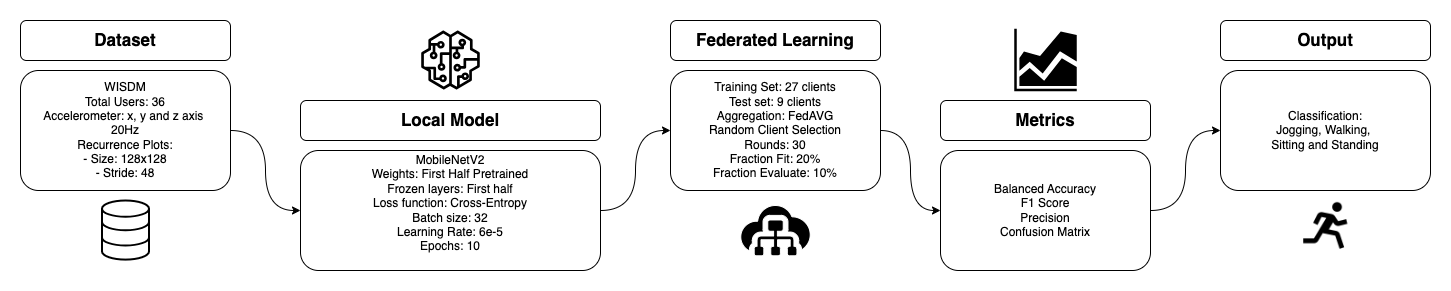


### Description

The image depicts a Federated Learning workflow for human activity recognition. Below, we explain each stage:
1. Dataset:
* WISDM.
* 36 users.
* Accelerometer with X, Y and Z axis with 20Hz.
* Recurrence Plots: With the accelerometer data, recurrence plots of size 128x128 are built with a stride of 48 samples.

2. Local Model:
The local model architecture consists of:
* A pretrained MobileNetV2 backbone to extract features efficiently while leveraging pretrained weights.
* A modified input convolution layer to accommodate inputs with 4 channels instead of the standard 3 channels.
* A custom fully connected layer to adapt the classifier for the specified number of output classes.
* Loss Function: Cross Entropy Loss is used to optimize the model.:
* Optimizer: Adam optimizer is employed with a learning rate of 5e-6. 
* Training Configuration: The model is trained for 10 epochs with a batch size of 32.

3. Federated Learning:
* Training Set: 27 clients.
* Test Set: 9 clients.
* Agreggation Strategy: Federated Average (FedAVG).
* Client Splitting: Clients are split between training and evaluation sets by their id. The last 9 clients are use as test dataset.
* Client Selection: Random client selection is used in each round of federated learning.
* Training Rounds: The model is trained over 30 rounds.
* Fraction Fit: Only 40% of the clients are used to fit the model during each round.
* Fraction Evaluate: 20% of the clients are used for evaluation in each round.

4. Metrics:
The metrics used to evaluate the model are (see Section IV for more information):
* Balanced Accuracy.
* Precision.
* F1 Score.
* Confusion Matrix
  
5. Output:
The network outputs the classification between four activities: Jogging, Walking, Sitting or Standing.




### Architecture Details
The **ModifiedMobileNetV2** class builds upon the pretrained MobileNetV2 model with the following key adjustments:

1. **Input Layer Modification**:
   - The default MobileNetV2 expects 3-channel input images (RGB). 
   - This implementation modifies the input layer (`Conv2d`) to handle 4-channel input data, matching the recurrence plot data used in this task.

2. **Custom Classification Layer**:
   - The final classification layer is replaced with a fully connected (`Linear`) layer. 
   - This layer's output size is set to match the number of target classes (`NUM_CLASSES`), allowing the model to adapt to the classification task.

3. **Pretrained Weights**:
   - The model initializes using pretrained MobileNetV2 weights to leverage transfer learning. 
   - These weights are loaded from an external file (`mobilenet_v2-b0353104.pth`) to improve model performance and speed up training.

### Forward Method
The `forward` method passes input tensors through the modified MobileNetV2 architecture, producing predictions based on the adapted classifier.

### Key Advantages
- **Efficiency**: MobileNetV2 is a lightweight and efficient architecture, ideal for tasks with resource constraints.
- **Adaptability**: Modifying the input and output layers ensures compatibility with non-standard datasets.
- **Transfer Learning**: Pretrained weights provide a strong initialization, reducing the training time and improving accuracy.

This proposed model is well-suited for the classification task, leveraging the robustness of MobileNetV2 while incorporating necessary customizations.


In [52]:
class ModifiedMobileNetV2(nn.Module):
    def __init__(self, num_classes):
        super(ModifiedMobileNetV2, self).__init__()
        # Load MobileNetV2 with pretrained weights
        self.base_model = models.mobilenet_v2(weights=None)
        self.base_model.load_state_dict(torch.load(f"{PATH}/mobilenet_v2-b0353104.pth"))
        
        # Modify the input layer to handle 4 channels instead of 3
        self.base_model.features[0][0] = nn.Conv2d(
            in_channels=num_classes, out_channels=32, kernel_size=3, stride=2, padding=1, bias=False
        )
        
        # Replace the final layer to match the number of classes
        self.base_model.classifier[1] = nn.Linear(self.base_model.last_channel, num_classes)
        
    def forward(self, x):
        return self.base_model(x)

The `test(net, testloader)` function evaluates the performance of a neural network (`net`) on a test dataset (`testloader`). It computes key metrics such as **loss**, **balanced accuracy**, **F1 score**, **precision**, and a **normalized confusion matrix**. The function uses PyTorch's `CrossEntropyLoss` and metrics from `sklearn` to assess the model's predictions, ensuring a comprehensive evaluation of its performance.


In [53]:
def test(net, testloader):
    """Evaluate the PEN network on the entire test set and return various metrics."""
    try:
        criterion = torch.nn.CrossEntropyLoss()
        correct, total, loss = 0, 0, 0.0
        net.eval()
        
        all_labels = []
        all_predictions = []

        with torch.no_grad():
            for batch in testloader:
                data, labels = batch["data"].to(DEVICE), batch["label"].to(DEVICE)
                outputs = net(data)

                loss += criterion(outputs, labels).item()
                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())

        # Calculate metrics
        loss /= len(testloader.dataset)
        balanced_acc = balanced_accuracy_score(all_labels, all_predictions)
        f1 = f1_score(all_labels, all_predictions, average='weighted')
        precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
        conf_matrix = confusion_matrix(all_labels, all_predictions, normalize='true').round(2)

        return loss, balanced_acc, f1, precision, conf_matrix

    except Exception as e:
        print(f"An error occurred (test): {e}")
        return None, None, None, None, None


The `train(net, trainloader, epochs: int, verbose=False)` function trains a PyTorch model (`net`) using data from a `trainloader` for a specified number of epochs. It employs **CrossEntropyLoss** as the loss function and the **Adam optimizer** by default. Training loss is computed and stored for each epoch, and detailed progress, including loss and epoch duration, can be printed if `verbose` is enabled. Returns a list of training losses for all epochs.


In [54]:
def train(net, trainloader, epochs: int, verbose=False):
    """
    Train the model with early stopping and evaluate it at each epoch.

    Parameters:
    - net: PyTorch model to be trained.
    - trainloader: DataLoader object containing the training data.
    - epochs: Number of epochs to train the model.
    - criterion: Loss function. If None, defaults to CrossEntropyLoss.
    - optimizer: Optimization algorithm. If None, defaults to Adam optimizer.
    - verbose: Boolean indicating whether to print detailed information during training.

    Returns:
    - train_loss: List of training losses for each epoch.
    """
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)
    
    net.train()
    train_losses = []

    for epoch in range(epochs):
        correct, total, epoch_loss = 0, 0, 0.0
        start_epoch_time = time.time()

        for batch in trainloader:
            data, labels = batch["data"].to(DEVICE), batch["label"].to(DEVICE)
            optimizer.zero_grad()
            outputs = net(data)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            total += labels.size(0)
            correct += (torch.max(outputs.data, 1)[1] == labels).sum().item()

        avg_loss = epoch_loss / len(trainloader)
        train_losses.append(avg_loss)

        end_epoch_time = time.time()
        epoch_time = end_epoch_time - start_epoch_time

        if verbose:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}, Time: {epoch_time:.2f} seconds')

    return train_losses

# <center> 4. Metrics </center>

The `evaluate` function computes various performance metrics to assess the effectiveness of the model. These metrics include **Balanced Accuracy**, **F1 Score**, **Precision**, and the **Confusion Matrix**. Below is a detailed explanation of each metric, their mathematical representations, and references to their respective documentation.

## 4.1. Balanced Accuracy

Balanced accuracy is a metric designed to address class imbalance by considering the recall (sensitivity) for each class individually and then averaging these values. It is particularly useful when the dataset contains imbalanced classes.

For a multi-class classification problem with $C$ classes, the **balanced accuracy** is calculated as the average of the recall for each class:

$$
\text{Balanced Accuracy} = \frac{1}{C} \sum_{i=1}^{C} \frac{TP_i}{TP_i + FN_i}
$$

Where:
- $TP_i$ = True Positives for class $i$
- $FN_i$ = False Negatives for class $i$
- $C$ = Total number of classes (in this case, 4)

This metric can be computed using the `balanced_accuracy_score` function from the `sklearn` library. For more information, refer to the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html).

## 4.2. F1 Score

The F1 score is the harmonic mean of precision and recall, providing a single metric that balances both concerns. It is particularly useful when the class distribution is imbalanced, as it avoids the bias towards the majority class.

### Formula:
$$
F1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}
$$
Where:
- Precision is the proportion of positive predictions that are actually correct.
- Recall is the proportion of actual positives that were correctly identified.

The `f1_score` function from `sklearn` is used to calculate this metric. For more details, check the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html).

## 4.3. Precision

Precision measures the accuracy of positive predictions. It is defined as the ratio of correctly predicted positive observations to the total predicted positive observations. It is important when the cost of false positives is high.

### Formula:
$$
\text{Precision} = \frac{TP}{TP + FP}
$$
Where:
- $TP$ = True Positives
- $FP$ = False Positives

Precision can be calculated using the `precision_score` function from the `sklearn` library. For more details, visit the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html).

## 4.4. Confusion Matrix

A confusion matrix provides a detailed breakdown of the predictions made by the model, showing the counts of true positives, true negatives, false positives, and false negatives. It is a useful tool to understand where the model is making mistakes, especially in multi-class classification tasks.

### Formula:
The confusion matrix  with 4 classes can be represented as:

$$
\begin{bmatrix}
TP_1 & FP_1 & FP_1 & FP_1 \\
FN_2 & TP_2 & FP_2 & FP_2 \\
FN_3 & FN_3 & TP_3 & FP_3 \\
FN_4 & FN_4 & FN_4 & TP_4 \\
\end{bmatrix}
$$
Where:
- $TP_i$ = True Positives for class $i$ (correctly predicted instances of class $i$).
- $FN_i$ = False Negatives for class $i$ (instances of class $i$ incorrectly predicted as other classes).
- $FP_i$ = False Positives for class $i$ (instances not belonging to class $i$ incorrectly predicted as class $i$).
  

In the evaluation function, the confusion matrix is normalized to provide proportions instead of raw counts. The `confusion_matrix` function from `sklearn` is used to compute this metric. You can find more information in the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).

These metrics provide a comprehensive view of the model's performance, particularly in the context of imbalanced datasets and multi-class classification. Each metric gives valuable insights into different aspects of the model's prediction capabilities.


# <center> 5. Model Training </center>

Below, `ModifiedMobileNetV2` model is initialized for training, setting up the loss function (`CrossEntropyLoss`) and optimizer (`Adam`). It employs a transfer learning strategy by initially freezing all layers of the base model (`base_model`) to prevent their weights from being updated during training. Then, it selectively unfreezes 50% of the base model's layers, prioritizing the classifier and feature extraction layers, enabling fine-tuning.


In [55]:
def freeze_and_clean_layers(model, unfrozen_layers):
    frozen = 0
    
    # Freeze all layers in the model initially
    for param in model.base_model.parameters():
        param.requires_grad = False
    
    # Unfreeze and clean the classifier layers first
    for layer in reversed(list(model.base_model.classifier.children())):
        if frozen < unfrozen_layers:
            for param in layer.parameters():
                param.requires_grad = True
                if hasattr(layer, 'reset_parameters'):
                    layer.reset_parameters()  # Clean weights
            frozen += 1

    # Unfreeze and clean the feature layers next
    for layer in reversed(list(model.base_model.features.children())):
        if frozen < unfrozen_layers:
            for param in layer.parameters():
                param.requires_grad = True
                if hasattr(layer, 'reset_parameters'):
                    layer.reset_parameters()  # Clean weights
            frozen += 1


In [56]:
model = ModifiedMobileNetV2(NUM_CLASSES).to(DEVICE)
UNFROZEN_LAYERS = len(list(model.base_model.parameters())) * 0.5
freeze_and_clean_layers(model, UNFROZEN_LAYERS)


In [57]:
summary(model, (NUM_CLASSES, WINDOW_SIZE, WINDOW_SIZE), device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]           1,152
       BatchNorm2d-2           [-1, 32, 64, 64]              64
             ReLU6-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 32, 64, 64]             288
       BatchNorm2d-5           [-1, 32, 64, 64]              64
             ReLU6-6           [-1, 32, 64, 64]               0
            Conv2d-7           [-1, 16, 64, 64]             512
       BatchNorm2d-8           [-1, 16, 64, 64]              32
  InvertedResidual-9           [-1, 16, 64, 64]               0
           Conv2d-10           [-1, 96, 64, 64]           1,536
      BatchNorm2d-11           [-1, 96, 64, 64]             192
            ReLU6-12           [-1, 96, 64, 64]               0
           Conv2d-13           [-1, 96, 32, 32]             864
      BatchNorm2d-14           [-1, 96,

In [58]:
train_losses = train(
    net=model,
    trainloader=train_loader,
    epochs=NUM_EPOCHS,
    verbose=True
)

print("Training complete.")

Epoch [1/10], Loss: 1.3805, Time: 26.93 seconds
Epoch [2/10], Loss: 1.2698, Time: 19.01 seconds
Epoch [3/10], Loss: 1.1846, Time: 19.89 seconds
Epoch [4/10], Loss: 1.0999, Time: 18.60 seconds
Epoch [5/10], Loss: 1.0414, Time: 18.39 seconds
Epoch [6/10], Loss: 0.9472, Time: 13.81 seconds
Epoch [7/10], Loss: 0.8642, Time: 17.00 seconds
Epoch [8/10], Loss: 0.8283, Time: 18.49 seconds
Epoch [9/10], Loss: 0.7770, Time: 15.81 seconds
Epoch [10/10], Loss: 0.7371, Time: 14.89 seconds
Training complete.


In [59]:
_, balanced_acc, precision, f1, conf_matrix = test(model, test_loader)
print(f"  Balanced Accuracy: {balanced_acc:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  F1 Score: {f1:.4f}")
print(f"  Confusion Matrix: \n{conf_matrix.round(2)}")

  Balanced Accuracy: 0.7127
  Precision: 0.7037
  F1 Score: 0.7580
  Confusion Matrix: 
[[0.4  0.49 0.08 0.03]
 [0.02 0.93 0.05 0.  ]
 [0.   0.01 0.65 0.33]
 [0.   0.   0.12 0.87]]


# <center> 6. Federated Simulation with Flower </center>

The`set_parameters(net, parameters)` and `get_parameters(net)` functions facilitate the integration of a PyTorch model (`net`) with Flower FL for federated learning.  
- **`set_parameters`**: Updates the model's state dictionary with weights provided as a list of NumPy arrays.  
- **`get_parameters`**: Extracts the model's current parameters as a list of NumPy arrays, enabling their sharing across federated clients.  
Both functions ensure seamless parameter exchange between the model and the federated learning framework.


In [60]:
def set_parameters(net, parameters: List[np.ndarray]):
    try:
        params_dict = zip(net.state_dict().keys(), parameters)
        state_dict = OrderedDict({k: torch.from_numpy(np.copy(v)) for k, v in params_dict})
        net.load_state_dict(state_dict, strict=True)
    except Exception as e:
        print(f"An error occurred (set_parameters): {e}")


def get_parameters(net) -> List[np.ndarray]:
    try:
        return [val.cpu().numpy() for _, val in net.state_dict().items()]
    except Exception as e:
        print(f"An error occurred (get_parameters): {e}")
        return None

The `FlowerClient` customizes the Flower FL `NumPyClient` interface to integrate a PyTorch model (`net`) with federated learning.  
- **`get_parameters`**: Retrieves the model's current weights for federated aggregation.  
- **`fit`**: Trains the model using local training data (`trainloader`) and updates its parameters.  
- **`evaluate`**: Evaluates the model on a validation dataset (`valloader` or `test_loader`) and computes metrics like **loss**, **balanced accuracy**, **F1 score**, and **precision**.  
This implementation supports federated learning by handling model updates and local evaluation seamlessly. In the case that the clients `trainloader` and `valloader` are the same object, the evaluation will be made with the global `testloader`. 


In [61]:
class FlowerClient(NumPyClient):
    def __init__(self, net, trainloader, valloader):
        self.net = net
        self.trainloader = trainloader
        self.valloader = valloader

    def get_parameters(self, config):
        return get_parameters(self.net)

    def fit(self, parameters, config):
        set_parameters(self.net, parameters)
        train_losses = train(
            net=self.net,
            trainloader=self.trainloader,
            epochs=NUM_EPOCHS,
            verbose=False
        )
        return get_parameters(self.net), len(self.trainloader), {}

    def evaluate(self, parameters, config):
        set_parameters(self.net, parameters)

        # If valloader and trainloader are the same, then this client will
        # be tested with the global test dataset
        if(self.valloader == self.trainloader):
            loss, balanced_acc, f1, precision, conf_matrix = test(self.net, test_loader)
        else:
            loss, balanced_acc, f1, precision, conf_matrix = test(self.net, self.valloader)
            
        return float(loss), len(self.valloader), {"accuracy": float(balanced_acc), "f1score": float(f1), "precision": float(precision)}

The `client_fn(context)` function creates and initializes a Flower federated learning client representing a single user.  
- **Loads a model**: Sets up a `ModifiedMobileNetV2` with specific layers frozen.  
- **Prepares data**: Retrieves the client-specific training and validation datasets based on the provided context. The load_client_data has `split=False`, so all this user's data will be used as `trainloader`. In this case the `valloader` receives the same object as `trainloader`, but is never used. The global `test_loader` will evaluate the model.  
- **Returns a client instance**: Wraps the model, data loaders, and logic into a `FlowerClient` for use in the federated learning framework.  
Handles exceptions gracefully to ensure robustness during client creation.


In [62]:
def client_fn(context) -> Client:
    """Create a Flower client representing a single user."""
    try:
        # Load model
        net = ModifiedMobileNetV2(NUM_CLASSES).to(DEVICE)
        freeze_and_clean_layers(net, UNFROZEN_LAYERS)
        
        partition_id = int(context)
        client_id = int(partition_id) + 1

        # Split = False doesn't create a validation dataset from this client
        # Then all data is used to train
        trainloader, valloader = load_client_data(partition_id=client_id, split=False)

        # If valloader is None, then this client will not use
        # it to test its local model. It will use the global test dataset
        if(valloader == None):
            valloader = trainloader
        
        return FlowerClient(net, trainloader, trainloader).to_client()
    except Exception as e:
        print(f"An error occurred (client_fn): {e}")
        return None

The `weighted_average(metrics)` function calculates weighted averages of metrics across multiple federated learning clients.  
- **Inputs**: A list of tuples, where each tuple contains the number of examples and a dictionary of metrics for a client.  
- **Outputs**: A dictionary with weighted averages of **accuracy**, **F1 score**, and **precision** across all clients, weighted by the number of examples per client.  
Handles exceptions to ensure reliable aggregation of metrics in the federated learning setting.


In [63]:
def weighted_average(metrics: List[Tuple[int, Metrics]]) -> Metrics:
    try:
        # Multiply accuracy of each client by number of examples used
        accuracies = [num_examples * m["accuracy"] for num_examples, m in metrics]
        f1s = [num_examples * m["f1score"] for num_examples, m in metrics]
        precisions = [num_examples * m["precision"] for num_examples, m in metrics]
        examples = [num_examples for num_examples, _ in metrics]

        # Aggregate and return custom metric (weighted average)
        return {"accuracy": sum(accuracies) / sum(examples), "f1score": sum(f1s) / sum(examples), "precision": sum(precisions) / sum(examples)}
    except Exception as e:
        print(f"An error occurred (weighted_average): {e}")
        return None

The `server_evaluate_fn(server_round, parameters, config)` function evaluates the global model on a test dataset at the server side during federated learning.  
- **Loads and updates the model**: Initializes a `ModifiedMobileNetV2` and applies the received global parameters to its state.  
- **Evaluates performance**: Computes **loss**, **balanced accuracy**, **F1 score**, and **precision** on the test dataset.  
- **Outputs**: Returns the test loss and a dictionary containing the evaluated metrics.  
Ensures robust evaluation for tracking global model performance across rounds.


In [64]:
def server_evaluate_fn(server_round:int, parameters, config):
    try:
        # Load model
        model = ModifiedMobileNetV2(NUM_CLASSES).to(DEVICE)
        freeze_and_clean_layers(model, UNFROZEN_LAYERS)

        params_dict = zip(model.state_dict().keys(), parameters)
        state_dict = OrderedDict({k: torch.from_numpy(np.copy(v)) for k, v in params_dict})
        model.load_state_dict(state_dict, strict=True)
        
        loss, balanced_acc, f1, precision, conf_matrix = test(model, test_loader)

        return float(loss), {"accuracy": float(balanced_acc), "f1score": float(f1), "precision": float(precision), "conf_matrix": conf_matrix}
    except Exception as e:
        print(f"An error occurred (server_evaluate_fn): {e}")
        return None, None


### Simulation

In [65]:
# Create FedAvg strategy
strategy = FedAvg(
    fraction_fit=0.2,  # Sample % of available clients for training
    fraction_evaluate=0.1,  # Sample % of available clients for evaluation
    min_fit_clients=1,  # sample  clients for training
    min_evaluate_clients=1,  # sample clients for evaluation
    min_available_clients=1,  # Wait until all clients are available
    evaluate_metrics_aggregation_fn=weighted_average,
    evaluate_fn=server_evaluate_fn,
)

# Configure the server for 5 rounds of training
config = ServerConfig(num_rounds=NUM_ROUNDS)

hist = start_simulation(
    num_clients=NUM_CLIENTS_TRAIN,
    client_fn=client_fn,
    strategy=strategy,
    config=config,
    client_resources={'num_cpus': 8, 'num_gpus': 0.0}
)

INFO flwr 2024-12-06 19:06:27,935 | app.py:178 | Starting Flower simulation, config: ServerConfig(num_rounds=30, round_timeout=None)
2024-12-06 19:06:33,920	INFO worker.py:1621 -- Started a local Ray instance.
INFO flwr 2024-12-06 19:06:35,639 | app.py:213 | Flower VCE: Ray initialized with resources: {'accelerator_type:A100': 1.0, 'node:__internal_head__': 1.0, 'node:10.233.83.47': 1.0, 'object_store_memory': 17574767001.0, 'memory': 35149534004.0, 'CPU': 32.0, 'GPU': 1.0}
INFO flwr 2024-12-06 19:06:35,640 | app.py:219 | Optimize your simulation with Flower VCE: https://flower.dev/docs/framework/how-to-run-simulations.html
INFO flwr 2024-12-06 19:06:35,640 | app.py:242 | Flower VCE: Resources for each Virtual Client: {'num_cpus': 8, 'num_gpus': 0.0}
INFO flwr 2024-12-06 19:06:35,648 | app.py:288 | Flower VCE: Creating VirtualClientEngineActorPool with 4 actors
INFO flwr 2024-12-06 19:06:35,649 | server.py:89 | Initializing global parameters
INFO flwr 2024-12-06 19:06:35,649 | server.p

# <center> 7. Results </center>




In [66]:
best_tuple = max(hist.metrics_centralized['accuracy'], key=lambda x: x[1])  # Compare by the second element

best_index, best_value = best_tuple
print(f"Accuracy: {hist.metrics_centralized['accuracy'][best_index][1]}")
print(f"F1 Score: {hist.metrics_centralized['f1score'][best_index][1]}")
print(f"Precision: {hist.metrics_centralized['precision'][best_index][1]}")

Accuracy: 0.7995042498223379
F1 Score: 0.8035515852156099
Precision: 0.8059250879647529


In [67]:
def plot_metrics_by_round(data, metric, legend, is_loss=False):
    df = pd.DataFrame(data, columns=["Round", "Accuracy"])
    # Set the style
    # Set the style
    sns.set_theme(style="dark")

    # Create the line plot with customizations
    plt.figure(figsize=(10, 6))
    sns.lineplot(x="Round", y="Accuracy", data=df, marker="o", color="royalblue", linewidth=2.5)

    # Customize the title and labels
    plt.title(f"{metric} per Round ({legend})", fontsize=16, fontweight='bold')
    plt.xlabel("Round", fontsize=14)
    plt.ylabel(metric, fontsize=14)

    # Customize the grid
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)

    # Customize the ticks
    plt.xticks(ticks=np.arange(df["Round"].min()-1, df["Round"].max() +1 , 10), fontsize=12)  # Ensure only integer rounds are shown on x-axis
    plt.yticks(fontsize=12)

    # Add a range for the y-axis for better visibility
    if(not is_loss):
        plt.ylim(0, 1)

    # Display the plot
    plt.show()

In [ ]:
plot_metrics_by_round(hist.losses_distributed, 'Loss', 'Server', True)

In [69]:
def plot_multiple_metrics_by_round(data1, data2, data3, legend):
    # Convert data to DataFrames
    df1 = pd.DataFrame(data1, columns=["Round", "Metric"])
    df2 = pd.DataFrame(data2, columns=["Round", "Metric"])
    df3 = pd.DataFrame(data3, columns=["Round", "Metric"])
    
    # Set the style
    sns.set_theme(style="dark")
    
    # Create the main plot
    plt.figure(figsize=(10, 6))
    
    # Plot each metric with different styles
    sns.lineplot(x="Round", y="Metric", data=df1, marker="o", color="royalblue", linewidth=2.5, label="Accuracy")
    sns.lineplot(x="Round", y="Metric", data=df2, marker="s", color="forestgreen", linewidth=2.5, label="F1 Score")
    sns.lineplot(x="Round", y="Metric", data=df3, marker="^", color="darkorange", linewidth=2.5, label="Precision")
    
    # Customize the title and labels
    plt.title(f"Metrics per Round ({legend})", fontsize=16, fontweight='bold')
    plt.xlabel("Round", fontsize=14)
    plt.ylabel("Value", fontsize=14)
    
    # Customize the grid
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    
    # Calculate and set x-axis ticks
    round_ticks = range(0, max(df1["Round"].max(), df2["Round"].max(), df3["Round"].max()) + 10, 10)
    plt.xticks(ticks=round_ticks, fontsize=12)  # Ensure only integer rounds are shown on x-axis
    
    # Customize the y-axis ticks
    plt.yticks(fontsize=12)
    
    # Set y-axis limits
    plt.ylim(0.2, 1.0)
    
    # Add a legend
    plt.legend(title="Metrics", title_fontsize='13', fontsize='12')
    
    # Inset plot for the last 5 values
    inset_axes = plt.gca().inset_axes([0.6, 0.1, 0.35, 0.35])  # Position inset: [left, bottom, width, height]
    sns.lineplot(x="Round", y="Metric", data=df1.tail(5), marker="o", color="royalblue", linewidth=2.0, ax=inset_axes)
    sns.lineplot(x="Round", y="Metric", data=df2.tail(5), marker="s", color="forestgreen", linewidth=2.0, ax=inset_axes)
    sns.lineplot(x="Round", y="Metric", data=df3.tail(5), marker="^", color="darkorange", linewidth=2.0, ax=inset_axes)
    
    # Annotate the last point in the inset
    for df, color, shift in zip([df1, df2, df3], ["royalblue", "forestgreen", "darkorange"], [0, 0.5, 1]):
        last_point = df.tail(5).iloc[-1]
        inset_axes.text(last_point["Round"] + shift, last_point["Metric"], 
                        f"{last_point['Metric']:.2f}", 
                        fontsize=10, fontweight='bold', color=color,
                        ha='right', va='bottom')
    
    # Customize the inset plot
    inset_axes.set_xlim(df1["Round"].max() - 4, df1["Round"].max())  # Set x-axis range for last 5 rounds
    #inset_axes.set_ylim(0.2, 1.0)  # Match y-axis limits to the main plot
    inset_axes.set_title("Last 5 Rounds", fontsize=12)
    inset_axes.set_ylabel("Value")
    inset_axes.grid(True, which='both', linestyle='--', linewidth=0.5)
    
    # Display the plot
    plt.show()

In [ ]:
plot_multiple_metrics_by_round(hist.metrics_centralized['accuracy'], hist.metrics_centralized['f1score'], hist.metrics_centralized['precision'], 'Server')

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=hist.metrics_centralized['conf_matrix'][best_index][1], display_labels=list(activity_mapping.keys()))
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.xticks(rotation=45)
plt.show()

In [ ]:
from datetime import datetime
import os
import json

# Define the folder structure and ensure it exists
os.makedirs(PATH, exist_ok=True)  # Create folder if it doesn't exist

# Function to manually serialize the flwr.server.History object
def serialize_history(hist):
    # Prepare a dictionary to hold the serialized data
    serialized_data = {}

    # Serialize loss data
    serialized_data['loss'] = {
        'distributed': [v for k, v in hist.losses_distributed],
        'centralized': [v for k, v in hist.losses_centralized]
    }

    # Serialize metrics data
    serialized_data['metrics'] = {
        'distributed': {
            'accuracy': [v for k, v in hist.metrics_distributed['accuracy']],
            'f1score': [v for k, v in hist.metrics_distributed['f1score']],
            'precision': [v for k, v in hist.metrics_distributed['precision']]
        },
        'centralized': {
            'accuracy': [v for k, v in hist.metrics_centralized['accuracy']],
            'f1score': [v for k, v in hist.metrics_centralized['f1score']],
            'precision': [v for k, v in hist.metrics_centralized['precision']],
            'conf_matrix': hist.metrics_centralized['conf_matrix'][best_index][1].tolist()
        }
    }

    # Return the dictionary instead of converting it to JSON here
    return serialized_data

# Save the serialized history to a JSON file
def save_history_as_json(hist):
    # Generate a filename with the given format
    datetime_str = datetime.now().strftime("%Y%m%d_%H%M%S")
    filename = f"{PATH}/recurrence_mobilenet_wisdm_{datetime_str}.json"
    
    # Serialize the history object
    serialized_hist = serialize_history(hist)
    
    # Save to JSON
    with open(filename, "w") as f:
        # Dump the dictionary directly to the JSON file
        json.dump(serialized_hist, f, indent=4)
    
    print(f"History saved to {filename}")

# Example to call the save function
save_history_as_json(hist) # Ensure hist is a valid object you want to serialize.


History saved to ./results/federated/recurrence_mobilenet_wisdm_20241206_195421.json


### Achieved Results
The plots below illustrate the results obtained from our experiments, visualized using the functions described earlier. These results provide insights into the training dynamics and model performance, which are analyzed in detail in this section.

The first plot shows the `Cross-Entropy Loss` computed for the global model (server) during the evaluation phase, performed at the end of each training round. The loss is calculated using the `test` function, where the server evaluates the global model on a dataset comprising the nine test users, as described in Section II.

As observed, the CrossEntropy Loss decreases steadily over the first nine rounds, demonstrating effective training progress. However, beyond the ninth round, the loss stabilizes and begins to oscillate within the interval [0.015, 0.035], indicating that further rounds do not lead to significant improvement. This plateau suggests that the model reaches its performance limit after the initial rounds of training. This trend aligns with the observations from the metrics plot, which provides additional evidence of the model's training behavior and will be discussed in the following section.

<img src="../misc/loss.png" alt="Loss" width="700">


The second plot presents the three metrics—Accuracy, F1 Score, and Precision—progressing closely together, as expected. Similar to the loss curve observed in the first plot, the training phase for these metrics is effective up to the ninth round. Beyond this point, the model reaches a plateau, with performance fluctuating between 60% and 80%. Notably, the highest values are achieved in the eighth round, with the following metrics:

* Accuracy: 79.95%
* F1 Score: 80.35%
* Precision: 80.59%

These results are comparable to the performance of the same model trained in a centralized (non-federated) environment, where an accuracy of approximately 83% was achieved. This indicates that the federated approach yields results close to the centralized counterpart while maintaining the benefits of distributed training.

<img src="../misc/metrics.png" alt="Metrics" width="700">


The final result is the Confusion Matrix, constructed during the evaluation phases. This matrix provides a detailed breakdown of the model's performance for each activity. The diagonal entries represent the number of correctly classified instances for each activity, highlighting the model's accuracy in identifying them. The off-diagonal values in each row indicate the number of misclassifications, showing how often the model confused a given activity (corresponding to the row) with other activities.

Two distinct groups are clearly visible in the Confusion Matrix. The first group consists of Walking and Jogging—activities characterized by similar movement patterns. The model misclassifies 27% of Walking instances as Jogging and 16% of Jogging instances as Walking. This overlap can likely be attributed to variations in individual movement styles. For instance, some users may walk at a brisk pace, while others may jog at a slower pace, leading to overlap in the motion dynamics and subsequent misclassification by the model.

The second group consists of the Sitting and Standing activities, which also share similar movement characteristics. Since our model does not utilize gyroscope data, distinguishing between these two activities becomes more challenging when relying solely on accelerometer data. We anticipate that the model's performance will improve with the inclusion of additional sensors, such as the gyroscope, which can provide more detailed information about the user's movement and posture.

<img src="../misc/conf_matrix.png" alt="Confusion Matrix" width="500">

# <center> 8. Conclusion </center>



## Thanks for your attention!